<a href="https://colab.research.google.com/github/thahakm/ml-projects/blob/main/nlptask(email).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
train = pd.read_csv("/content/train.csv")
test = pd.read_csv("/content/test.csv")

In [2]:
df = pd.concat([train, test], ignore_index=True)

In [3]:
df

,text,label
0,Thanks for your message. I will review the pre...,non-spam
1,"Dear customer, your bank account has been sele...",spam
2,"Dear customer, your email account has been sel...",spam
3,Thanks for your message. I will review the pre...,non-spam
4,Your appointment is confirmed for Friday at 2:...,non-spam
...,...,...
795,"Your loan is pre-approved. Get up to ₹10,000 w...",spam
796,"URGENT: Your account is eligible for a ₹10,000...",spam
797,Don't forget to bring your phone for the the p...,non-spam
798,Please find the presentation attached for tomo...,non-spam


In [4]:
df.label = df.label.map({
    "spam":0,
    "non-spam":1
})

In [5]:
df

,text,label
0,Thanks for your message. I will review the pre...,1
1,"Dear customer, your bank account has been sele...",0
2,"Dear customer, your email account has been sel...",0
3,Thanks for your message. I will review the pre...,1
4,Your appointment is confirmed for Friday at 2:...,1
...,...,...
795,"Your loan is pre-approved. Get up to ₹10,000 w...",0
796,"URGENT: Your account is eligible for a ₹10,000...",0
797,Don't forget to bring your phone for the the p...,1
798,Please find the presentation attached for tomo...,1


In [6]:
df.shape

(800, 2)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    800 non-null    object
 1   label   800 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 12.6+ KB


In [8]:
df.describe()

,label
count,800.000000
mean,0.502500
std,0.500307
min,0.000000
25%,0.000000
50%,1.000000
75%,1.000000
max,1.000000


In [9]:
df.dtypes

,0
text,object
label,int64


In [10]:
opvalues = df.label.value_counts()

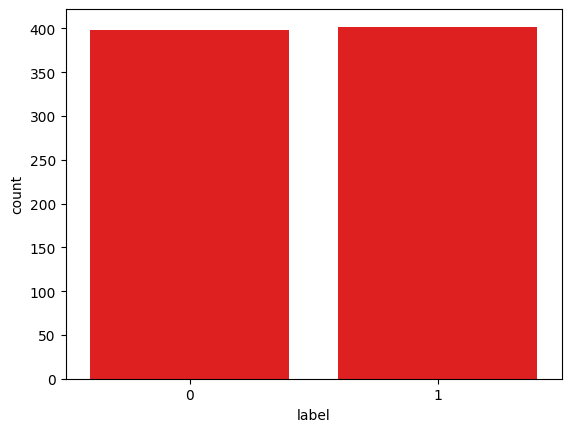

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
# plt.bar(opvalues.index,opvalues.values,color="g")
sns.countplot(x=df.label,color="r")
plt.show()

In [12]:
mail = df.text
mail

,text
0,Thanks for your message. I will review the pre...
1,"Dear customer, your bank account has been sele..."
2,"Dear customer, your email account has been sel..."
3,Thanks for your message. I will review the pre...
4,Your appointment is confirmed for Friday at 2:...
...,...
795,"Your loan is pre-approved. Get up to ₹10,000 w..."
796,"URGENT: Your account is eligible for a ₹10,000..."
797,Don't forget to bring your phone for the the p...
798,Please find the presentation attached for tomo...


In [13]:
import nltk
nltk.download('stopwords')
# nltk.download('punkt-tab')
nltk.download('punkt_tab')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [14]:
# TOKENISATION
from nltk.tokenize import word_tokenize

mail = mail.apply(lambda x: word_tokenize(x)).apply(lambda x:" ".join(x))
mail

,text
0,Thanks for your message . I will review the pr...
1,"Dear customer , your bank account has been sel..."
2,"Dear customer , your email account has been se..."
3,Thanks for your message . I will review the pr...
4,Your appointment is confirmed for Friday at 2:...
...,...
795,"Your loan is pre-approved . Get up to ₹10,000 ..."
796,"URGENT : Your account is eligible for a ₹10,00..."
797,Do n't forget to bring your phone for the the ...
798,Please find the presentation attached for tomo...


In [15]:
# removing special charecters
mail = mail.replace("[^a-zA-Z0-9]"," ",regex=True)
mail

,text
0,Thanks for your message I will review the pr...
1,Dear customer your bank account has been sel...
2,Dear customer your email account has been se...
3,Thanks for your message I will review the pr...
4,Your appointment is confirmed for Friday at 2 ...
...,...
795,Your loan is pre approved Get up to 10 000 ...
796,URGENT Your account is eligible for a 10 00...
797,Do n t forget to bring your phone for the the ...
798,Please find the presentation attached for tomo...


In [16]:
# emoving lesthan 3 charecter sentence
mail = mail.str.findall(r"\b[a-zA-Z]{3,}\b").str.join(" ")
mail

,text
0,Thanks for your message will review the presen...
1,Dear customer your bank account has been selec...
2,Dear customer your email account has been sele...
3,Thanks for your message will review the presen...
4,Your appointment confirmed for Friday Please a...
...,...
795,Your loan pre approved Get with quick approval...
796,URGENT Your account eligible for cash bonus Cl...
797,forget bring your phone for the the project se...
798,Please find the presentation attached for tomo...


In [17]:
# stemming
from nltk.stem import PorterStemmer
ps = PorterStemmer()
mail = mail.apply(lambda x:[ps.stem(i.lower()) for i in word_tokenize(x)]).apply(lambda x: " ".join(x))
mail

,text
0,thank for your messag will review the present ...
1,dear custom your bank account ha been select f...
2,dear custom your email account ha been select ...
3,thank for your messag will review the present ...
4,your appoint confirm for friday pleas arriv te...
...,...
795,your loan pre approv get with quick approv app...
796,urgent your account elig for cash bonu click w...
797,forget bring your phone for the the project se...
798,pleas find the present attach for tomorrow mee...


In [18]:
from nltk.corpus import stopwords
st_words = stopwords.words("english")
len(st_words)

198

In [19]:
# removing stopwords
mail = mail.apply(lambda x: [i for i in word_tokenize(x) if i not in st_words]).apply(lambda x :" ".join(x))
mail

,text
0,thank messag review present get back refer number
1,dear custom bank account ha select special rew...
2,dear custom email account ha select special re...
3,thank messag review present get back refer number
4,appoint confirm friday pleas arriv ten minut e...
...,...
795,loan pre approv get quick approv appli today
796,urgent account elig cash bonu click www claim ...
797,forget bring phone project session tomorrow
798,pleas find present attach tomorrow meet refer ...


In [20]:
# vectorisation
from sklearn.feature_extraction.text import TfidfVectorizer
vec = TfidfVectorizer()
data = vec.fit_transform(mail)
data

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 7397 stored elements and shape (800, 174)>

In [21]:
from sklearn.naive_bayes import MultinomialNB


In [22]:
x=data
y = df.label

In [23]:
from sklearn.model_selection import train_test_split
xtrain,xtest,ytrain,ytest = train_test_split(x,y,
                                             test_size=0.20,
                                             random_state=42)

In [24]:
mn = MultinomialNB()
mn.fit(xtrain,ytrain)

MultinomialNB()

In [25]:
ypred = mn.predict(xtest)
ypred

array([1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 1,
       1, 0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0,
       0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1,
       1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1,
       1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 0, 1, 0,
       1, 0, 1, 1, 0, 1])

In [29]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, f1_score
acc = accuracy_score(ytest, ypred)
print("accuracy score =",acc)
print("precision score = ",precision_score(ytest,ypred))
print("rrecall score = ",recall_score(ytest,ypred))
print("confusion matrix",confusion_matrix(ytest,ypred))
print("f1 score = ",f1_score(ytest,ypred))


accuracy score = 1.0
precision score =  1.0
rrecall score =  1.0
confusion matrix [[89  0]
 [ 0 71]]
f1 score =  1.0


checking external sms file


In [48]:
import pandas as pd

sms = pd.read_csv(
    "SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"]
)

In [49]:
sms


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...
5568,ham,Will ü b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...


In [50]:
sms['label']=sms['label'].map({
    "spam":0,
    "ham":1
})

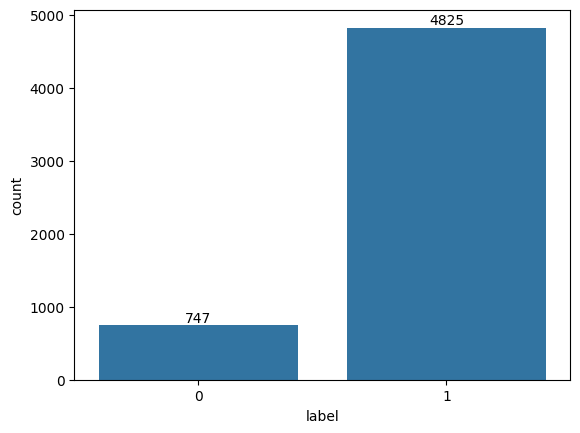

In [51]:
ax = sns.countplot(sms,x="label")
# to show bar exact count
for bars in ax.containers:
  ax.bar_label(bars)


In [52]:
text = sms.message

In [53]:
# "tokenisation"
from nltk.tokenize import word_tokenize

text = text.apply(lambda x: word_tokenize(x)).apply(lambda x: " ".join(x))
text

,message
0,"Go until jurong point , crazy .. Available onl..."
1,Ok lar ... Joking wif u oni ...
2,Free entry in 2 a wkly comp to win FA Cup fina...
3,U dun say so early hor ... U c already then sa...
4,"Nah I do n't think he goes to usf , he lives a..."
...,...
5567,This is the 2nd time we have tried 2 contact u...
5568,Will ü b going to esplanade fr home ?
5569,"Pity , * was in mood for that . So ... any oth..."
5570,The guy did some bitching but I acted like i '...


In [54]:
text=text.replace("[^a-zA-Z0-9]"," ",regex=True)
text

,message
0,Go until jurong point crazy Available onl...
1,Ok lar Joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...
3,U dun say so early hor U c already then sa...
4,Nah I do n t think he goes to usf he lives a...
...,...
5567,This is the 2nd time we have tried 2 contact u...
5568,Will b going to esplanade fr home
5569,Pity was in mood for that So any oth...
5570,The guy did some bitching but I acted like i ...


In [55]:
# emoving lesthan 3 charecter sentence
text = text.str.findall(r"\b[a-zA-Z]{3,}\b").str.join(" ")
text

,message
0,until jurong point crazy Available only bugis ...
1,lar Joking wif oni
2,Free entry wkly comp win Cup final tkts May Te...
3,dun say early hor already then say
4,Nah think goes usf lives around here though
...,...
5567,This the time have tried contact have won the ...
5568,Will going esplanade home
5569,Pity was mood for that any other suggestions
5570,The guy did some bitching but acted like inter...


In [57]:
from nltk.stem import PorterStemmer
ps = PorterStemmer()
text = text.apply(lambda x:[ps.stem(i.lower()) for i in word_tokenize(x)]).apply(lambda x:" ".join(x))
text

,message
0,until jurong point crazi avail onli bugi great...
1,lar joke wif oni
2,free entri wkli comp win cup final tkt may tex...
3,dun say earli hor alreadi then say
4,nah think goe usf live around here though
...,...
5567,thi the time have tri contact have won the pou...
5568,will go esplanad home
5569,piti wa mood for that ani other suggest
5570,the guy did some bitch but act like interest b...


In [58]:
from nltk.corpus import stopwords
st_words = stopwords.words("english")
len(st_words)

198

In [60]:
text = text.apply(lambda x:[i for i in word_tokenize(x)if i not in st_words]).apply(lambda x:" ".join(x))
text

,message
0,jurong point crazi avail onli bugi great world...
1,lar joke wif oni
2,free entri wkli comp win cup final tkt may tex...
3,dun say earli hor alreadi say
4,nah think goe usf live around though
...,...
5567,thi time tri contact pound prize claim easi ca...
5568,go esplanad home
5569,piti wa mood ani suggest
5570,guy bitch act like interest buy someth el next...


In [64]:
# vectorisation
from sklearn.feature_extraction.text import TfidfVectorizer
vec = TfidfVectorizer()
data1 = vec.fit_transform(text)
data1

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 42220 stored elements and shape (5572, 5921)>

In [67]:
# We must use the trained model instance 'mn' instead of the class name 'MultinomialNB'.
# Also, to align the features with what 'mn' expects (174 features),
# we use the vectorizer fitted on the original training 'mail' dataset to transform the new 'text'.

original_vec = TfidfVectorizer()
original_vec.fit(mail)
data_aligned = original_vec.transform(text)

ysms = mn.predict(data_aligned)
ysms

array([0, 1, 1, ..., 1, 0, 1])

In [69]:
accofsms = accuracy_score(sms.label,ysms)
accofsms

0.7480258435032304